# 05 · EDA: IPC codes and overlap between fields

**Needs:** the merged files from notebook 02, `ipc/ipc_titles.csv` and `ipc/ipc_technology.xlsx`. **Produces:** nothing.

Questions for this notebook:
1. How many IPC codes does a patent have?
2. Which IPC subclasses are the most frequent, and what do they mean?
3. Which IPC sections does each sector use?
4. What does each field look like in terms of IPC codes?
5. **How many patents could belong to more than one field?** We apply the WIPO rules to every patent.

In [1]:
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROC = Path("../data/processed")
IPC = Path("../ipc")

by_field = pd.read_parquet(PROC / "patents_2021-2026_by_field.parquet")
by_pub = pd.read_parquet(PROC / "patents_2021-2026_by_publication.parquet")

titles = pd.read_csv(IPC / "ipc_titles.csv", dtype=str, keep_default_na=False)
sub_title = titles[titles["level"] == "subclass"].set_index("symbol")["short_title"]
sec_title = titles[titles["level"] == "section"].set_index("symbol")["short_title"]

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

SECTORS = ["Electrical engineering", "Instruments", "Chemistry", "Mechanical engineering"]
COLORS = dict(zip(SECTORS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))
by_field["field"] = by_field["wipo_field_number"].astype(str).str.zfill(2) + " " + by_field["wipo_field_name"]
field_order = sorted(by_field["field"].unique())
field_sector = by_field.drop_duplicates("field").set_index("field")["wipo_sector"]

## 1. How many IPC codes per patent?

`n_ipc` counts all codes; `n_subclasses` counts distinct subclasses (the first 4 characters).
Several codes can belong to the same subclass.

In [2]:
by_pub[["n_ipc", "n_subclasses"]].describe().round(1)

,n_ipc,n_subclasses
count,63968.0,63968.0
mean,4.2,2.1
std,3.2,1.2
min,1.0,1.0
25%,2.0,1.0
50%,3.0,2.0
75%,5.0,3.0
max,109.0,22.0


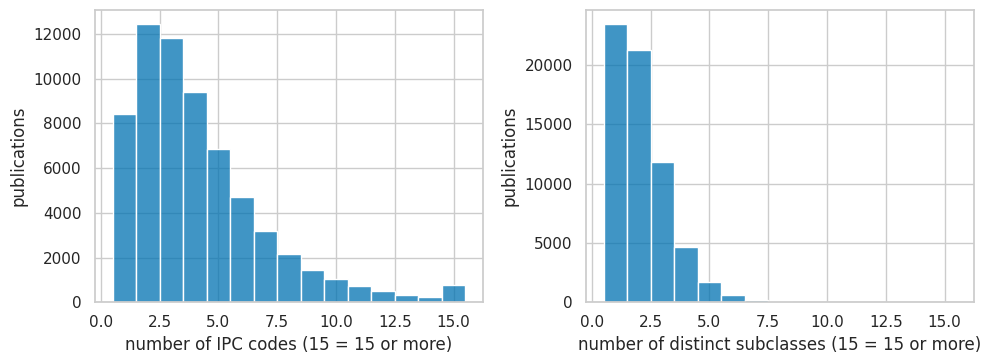

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, label in [(axes[0], "n_ipc", "IPC codes"), (axes[1], "n_subclasses", "distinct subclasses")]:
    sns.histplot(by_pub[col].clip(upper=15), discrete=True, color="#0072B2", ax=ax)
    ax.set_xlabel(f"number of {label} (15 = 15 or more)")
    ax.set_ylabel("publications")
plt.tight_layout()
plt.show()

Most patents have few codes and only one or two subclasses, but there is a long tail. By sector (using the *by field* table):

In [4]:
by_field.groupby("wipo_sector")[["n_ipc", "n_subclasses"]].agg(["mean", "median", "max"]).loc[SECTORS].round(1)

n_ipc             n_subclasses           
                        mean median  max         mean median max
wipo_sector                                                     
Electrical engineering   3.9    3.0   80          2.0    2.0  18
Instruments              3.6    3.0  109          2.0    2.0  22
Chemistry                5.1    4.0   93          2.5    2.0  13
Mechanical engineering   3.5    3.0   47          1.8    2.0  15

## 2. The most frequent subclasses

We count in how many publications each subclass appears, and use the titles from `ipc_titles.csv`.

625 distinct subclasses in the corpus


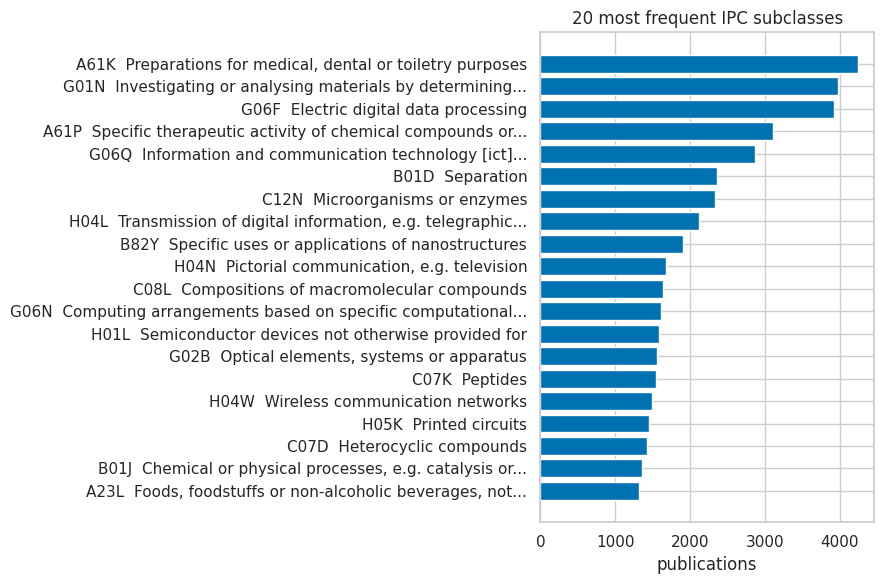

In [5]:
sub_counts = by_pub["ipc_subclasses"].explode().value_counts()
print(len(sub_counts), "distinct subclasses in the corpus")

top = sub_counts.head(20)
labels = [f"{code}  {textwrap.shorten(sub_title.get(code, '?'), width=58, placeholder='...')}" for code in top.index]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(labels[::-1], top.values[::-1], color="#0072B2")
ax.set_xlabel("publications")
ax.set_title("20 most frequent IPC subclasses")
plt.tight_layout()
plt.show()

Which codes could not be matched to a title?

In [6]:
missing_titles = [c for c in sub_counts.index if c not in sub_title.index]
print("subclasses without a title:", missing_titles)

subclasses without a title: []


## 3. IPC sections by sector

The first letter of an IPC code is its section (A to H). We compute, for each sector, the share of its patents with
**at least one** code in each section. A patent with codes in two sections counts in both.

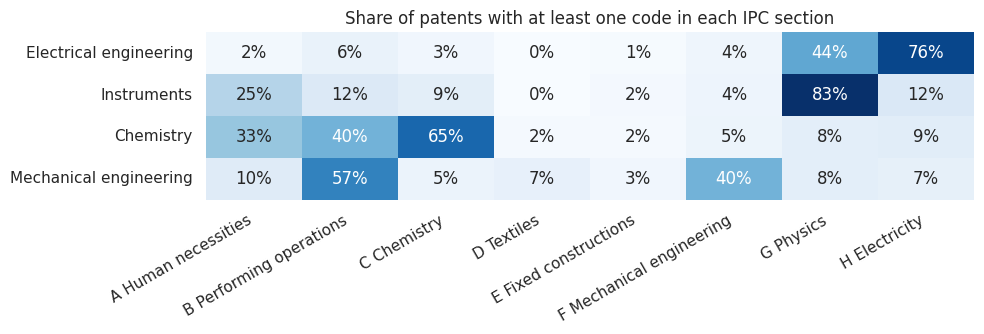

In [7]:
by_field["ipc_sections"] = by_field["ipc_subclasses"].map(lambda subs: sorted({s[0] for s in subs}))
sections = list("ABCDEFGH")

sec_share = pd.DataFrame(
    {s: by_field["ipc_sections"].map(lambda secs, s=s: s in secs).groupby(by_field["wipo_sector"]).mean() for s in sections}
).loc[SECTORS]
sec_share.columns = [f"{s} {sec_title[s][:22]}" for s in sections]

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(sec_share, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set_ylabel("")
ax.set_title("Share of patents with at least one code in each IPC section")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

WIPO fields cut across IPC sections: a sector is not a single section.

## 4. Each field in terms of IPC subclasses

For each field: how many distinct subclasses appear, and which three are the most frequent
(as a share of the field's publications).

In [8]:
rows = []
for field, g in by_field.groupby("field"):
    counts = g["ipc_subclasses"].explode().value_counts()
    top3 = ", ".join(f"{c} ({n / len(g):.0%})" for c, n in counts.head(3).items())
    rows.append({"field": field, "distinct subclasses": len(counts), "top 3 subclasses (share of field)": top3})

field_ipc = pd.DataFrame(rows).set_index("field").loc[field_order]
field_ipc

,distinct subclasses,top 3 subclasses (share of field)
field,,
"01 Electrical machinery, apparatus, energy",304,"H01M (22%), H02J (15%), H02K (9%)"
02 Audio-visual technology,257,"H05K (36%), H04N (34%), G09F (12%)"
03 Telecommunications,227,"H04B (43%), H01Q (22%), H04W (18%)"
04 Digital communication,119,"H04L (62%), H04W (44%), G06F (14%)"
05 Basic communication processes,164,"H03K (36%), H03M (23%), H03H (21%)"
06 Computer technology,197,"G06F (65%), G06N (26%), G06V (15%)"
07 IT methods for management,154,"G06Q (100%), G06F (41%), G06N (20%)"
08 Semiconductors,195,"H01L (49%), H10P (16%), H10K (15%)"
09 Optics,226,"G02B (53%), G02F (18%), G03B (14%)"


Some fields concentrate on a few subclasses (for example *IT methods for management* is built from one subclass,
`G06Q`), others are spread over many.

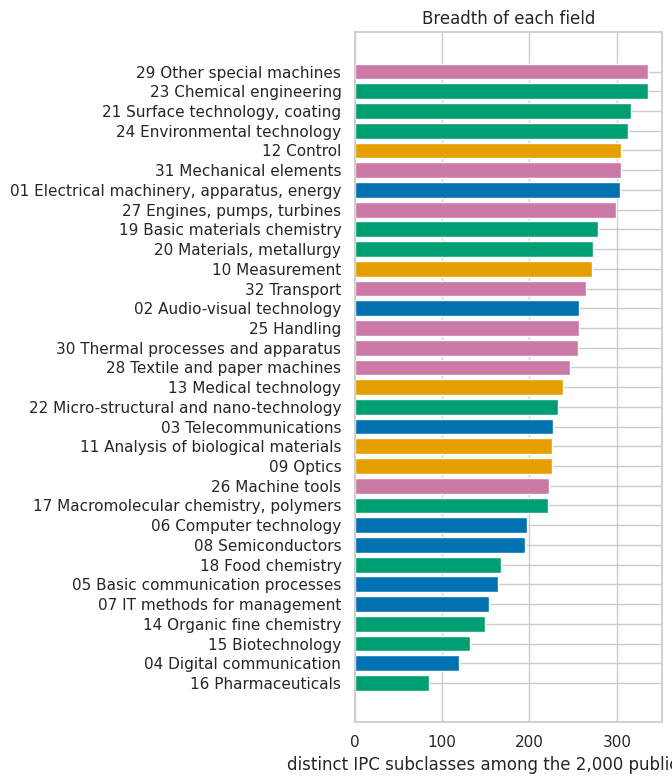

In [9]:
n_sub = field_ipc["distinct subclasses"].sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(n_sub.index, n_sub.values, color=[COLORS[field_sector[f]] for f in n_sub.index])
ax.set_xlabel("distinct IPC subclasses among the 2,000 publications")
ax.set_title("Breadth of each field")
plt.tight_layout()
plt.show()

## 5. Overlap: can a patent belong to several fields?

A patent was selected for **one** field, but it carries several IPC codes, and each code can fall under the rules of a different field.
To measure this, we apply the WIPO rules to **every** patent, for all 32 fields.

A rule such as `G06Q%` means "starts with `G06Q`". A patent matches a field if at least one of its codes matches at least one rule.

In [10]:
rules = pd.read_excel(IPC / "ipc_technology.xlsx", header=6)[["Field_number", "IPC_code"]]
rules = rules[rules["Field_number"] <= 32].copy()
rules["rule"] = rules["IPC_code"].str.upper().str.replace(r"\s+", "", regex=True)
assert rules["rule"].str.endswith("%").all()          # all rules are "starts with"

# prefixes of each field, e.g. 7 -> ("G06Q",)
prefixes = {int(n): tuple(g["rule"].str[:-1]) for n, g in rules.groupby("Field_number")}
print(len(rules), "rules for", len(prefixes), "fields")

667 rules for 32 fields


In [11]:
# which fields does each IPC code match? (computed once for every distinct code)
all_codes = set(c for s in by_pub["ipc_codes"] for c in s.split(";"))
code_fields = {c: {f for f, p in prefixes.items() if c.startswith(p)} for c in all_codes}
print(len(all_codes), "distinct IPC codes")

# fields matched by each publication = union over its codes
pub_fields = by_pub["ipc_codes"].map(lambda s: set().union(*(code_fields[c] for c in s.split(";"))))
by_pub["n_fields_matched"] = pub_fields.map(len)

34258 distinct IPC codes


**Check.** Every patent must match the field it was selected for. If this fails, the rules we apply differ from the query.

In [12]:
selected_ok = [set(sel) <= matched for sel, matched in zip(by_pub["wipo_field_numbers"], pub_fields)]
print("publications matching their selected field(s):", sum(selected_ok), "of", len(by_pub))

publications matching their selected field(s): 63968 of 63968


**How many fields does a patent match?**

In [13]:
dist = by_pub["n_fields_matched"].value_counts().sort_index()
pd.DataFrame({"publications": dist, "share": (dist / dist.sum()).round(3)})

,publications,share
n_fields_matched,,
1,29692,0.464
2,23682,0.370
3,8100,0.127
4,1950,0.030
5,421,0.007
6,102,0.002
7,14,0.000
8,3,0.000
9,4,0.000


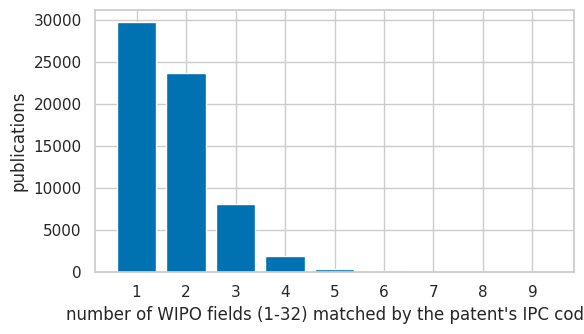

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dist.index.astype(str), dist.values, color="#0072B2")
ax.set_xlabel("number of WIPO fields (1-32) matched by the patent's IPC codes")
ax.set_ylabel("publications")
plt.tight_layout()
plt.show()

More than half of the patents match two or more fields, even though we selected each of them for one field only.
This is a property of the WIPO classification, not an error. The "field of selection" is **one** of the fields of a patent.
It also means that the 2,000 patents of a field are not a "pure" sample of that technology.

**Which fields overlap?** For the 2,000 patents selected for field *i* (rows), the share that also match field *j* (columns):

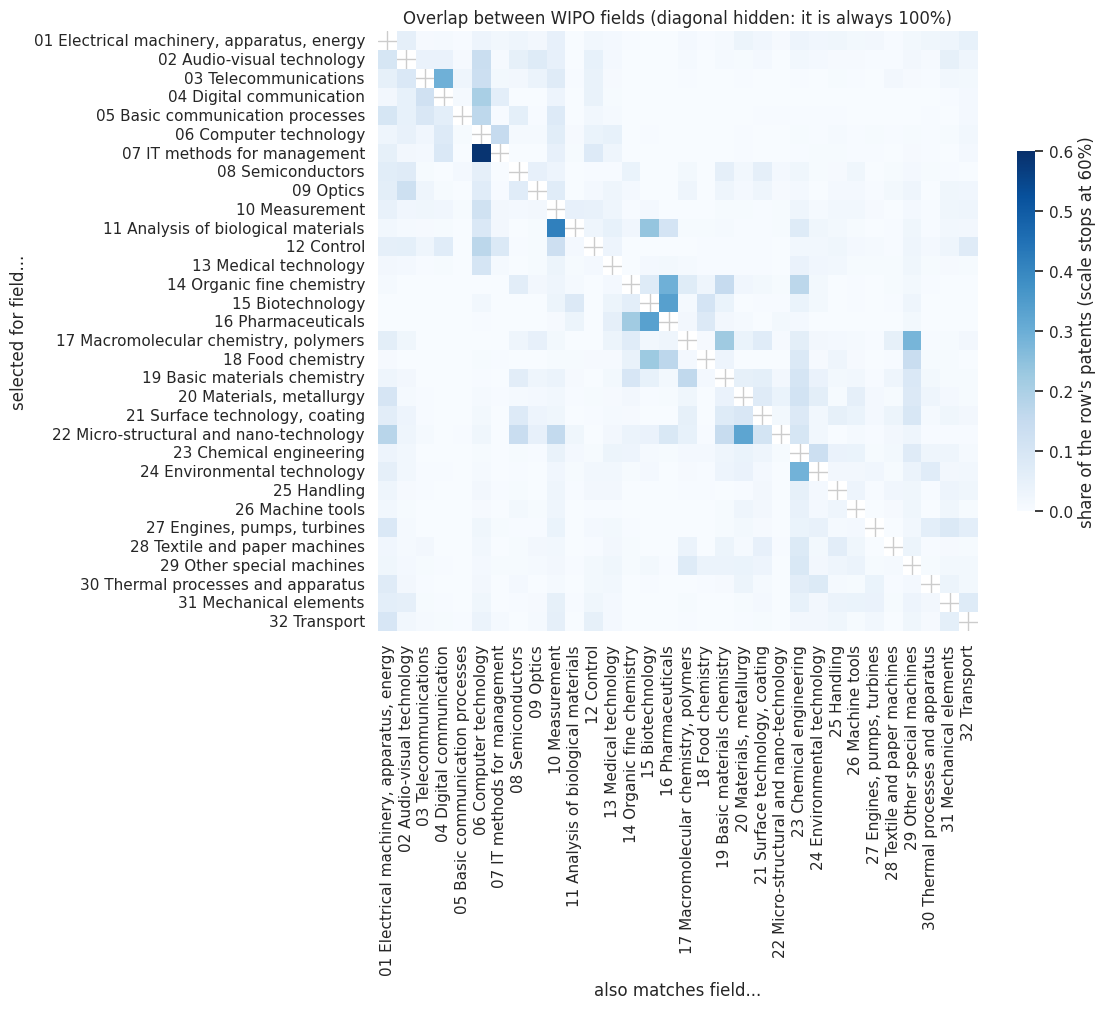

In [15]:
indicator = np.zeros((len(by_pub), 32), dtype=bool)
for k, matched in enumerate(pub_fields):
    for f in matched:
        indicator[k, f - 1] = True

position = pd.Series(np.arange(len(by_pub)), index=by_pub["publication_number"])
rows_idx = position[by_field["publication_number"]].to_numpy()

overlap = pd.DataFrame(indicator[rows_idx]).groupby(by_field["wipo_field_number"].to_numpy()).mean()
overlap.index = field_order
overlap.columns = field_order

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(overlap, mask=np.eye(32, dtype=bool), cmap="Blues", vmin=0, vmax=0.6, square=True,
            cbar_kws={"shrink": 0.6, "label": "share of the row's patents (scale stops at 60%)"}, ax=ax)
ax.set_xlabel("also matches field...")
ax.set_ylabel("selected for field...")
ax.set_title("Overlap between WIPO fields (diagonal hidden: it is always 100%)")
plt.tight_layout()
plt.show()

The strongest overlaps (row field → column field):

In [16]:
pairs = overlap.where(~np.eye(32, dtype=bool)).stack().sort_values(ascending=False)
pairs.head(12).rename("share").round(2)

07 IT methods for management             06 Computer technology          0.59
11 Analysis of biological materials      10 Measurement                  0.42
15 Biotechnology                         16 Pharmaceuticals              0.34
16 Pharmaceuticals                       15 Biotechnology                0.33
22 Micro-structural and nano-technology  20 Materials, metallurgy        0.32
03 Telecommunications                    04 Digital communication        0.30
14 Organic fine chemistry                16 Pharmaceuticals              0.29
24 Environmental technology              23 Chemical engineering         0.29
17 Macromolecular chemistry, polymers    29 Other special machines       0.28
11 Analysis of biological materials      15 Biotechnology                0.24
18 Food chemistry                        15 Biotechnology                0.23
17 Macromolecular chemistry, polymers    19 Basic materials chemistry    0.22
Name: share, dtype: float64

For each field, the share of its patents that match **at least one other field**:

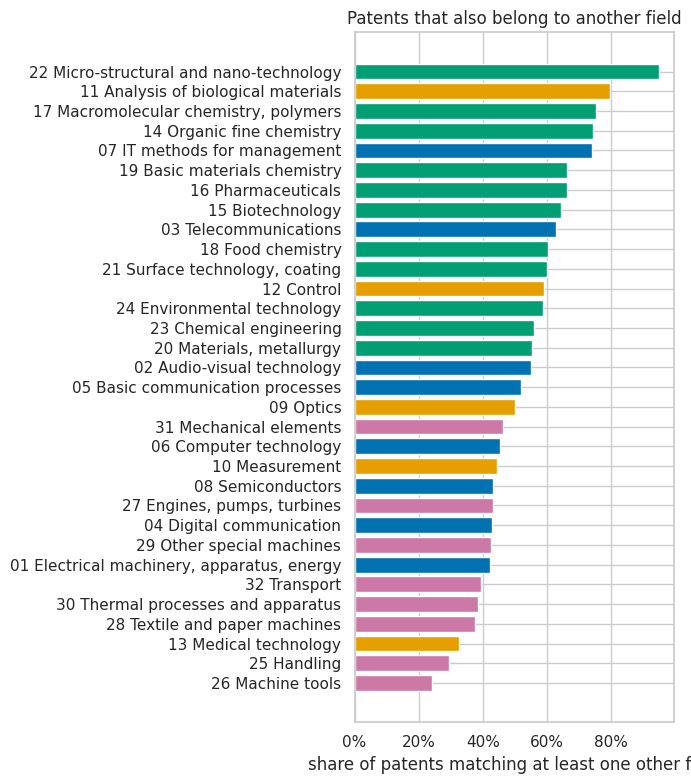

In [17]:
others = (indicator[rows_idx].sum(axis=1) > 1)
share_multi = pd.Series(others).groupby(by_field["field"].to_numpy()).mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(share_multi.index, share_multi.values, color=[COLORS[field_sector[f]] for f in share_multi.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("share of patents matching at least one other field")
ax.set_title("Patents that also belong to another field")
plt.tight_layout()
plt.show()

## What to take away

- A typical patent has 3 IPC codes in 2 subclasses. Chemistry patents have more codes than the other sectors.
- The rules applied here reproduce the selection exactly: every patent matches the field it was selected for. The SQL queries and the WIPO file agree.
- **Overlap is large.** More than half of the patents match two or more fields. The strongest overlaps are between
  neighbouring technologies: *IT methods for management* → *Computer technology*, *Analysis of biological materials* → *Measurement*,
  *Biotechnology* ↔ *Pharmaceuticals*.
- Some fields are defined by a single subclass (`G06Q` for *IT methods for management*, `G01N33` for *Analysis of biological materials*),
  others by dozens: breadth differs a lot.
- Implication for modelling: field labels are **not mutually exclusive**. A text classifier that predicts a single field will be penalised
  for patents that legitimately belong to two.

## Limits

- Fields 33–35 are not part of the data, so overlaps with *Furniture, games*, *Other consumer goods* and *Civil engineering* are not measured.
- Rules are applied to IPC codes as they appear in the data. Codes changed by IPC revisions can be missed.

## Try it yourself

1. Which IPC subclasses make *Medical technology* and *Pharmaceuticals* overlap? (Hint: use `A61` codes.)
2. For a field of your choice, list 5 patents that also match another field. Do the titles make sense in both fields?
3. In section 2, the top subclasses are dominated by a few fields. Repeat the chart for one sector only.